# 03 · Modelado Comparativo

Objetivo (PDF sección 3.3): entrenar y comparar los 4 modelos candidatos (Regresión Logística, Random Forest, LightGBM, XGBoost) sobre el split cronológico, y elegir el umbral costo-óptimo, que es la métrica de decisión del checkpoint 1.

In [1]:
import sys
sys.path.append('../src')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

from models import get_models
from evaluation import compute_metrics, business_cost

train_df = pd.read_parquet('../data/processed/train.parquet')
val_df = pd.read_parquet('../data/processed/val.parquet')

drop_cols = ['TransactionID', 'isFraud', 'TransactionDT', 'day']
feature_cols = [c for c in train_df.columns if c not in drop_cols]

print('train:', train_df.shape, ' val:', val_df.shape)
print('n features:', len(feature_cols))

train: (354324, 401)  val: (118108, 401)
n features: 397


Se excluyen TransactionID, que es solo un identificador, isFraud, que es el target, y TransactionDT/day, porque codifican la cronología exacta. Dejarlos como feature numérico crudo le permitiría al modelo memorizar el orden temporal en vez de aprender patrones que generalicen. Las señales temporales que sí importan ya quedan capturadas en hour_of_day, day_of_week y las variables de ventana de 24h.

## 1. Preparación de features por modelo

Los modelos de árbol (Random Forest, LightGBM, XGBoost) usan las features tal cual. La Regresión Logística necesita las variables escaladas, con un StandardScaler ajustado solo con train y aplicado después a val, sin fuga de información, porque de lo contrario el centinela -999 que usamos para imputar nulos terminaría dominando el modelo lineal.

In [2]:
X_train, y_train = train_df[feature_cols], train_df['isFraud']
X_val, y_val = val_df[feature_cols], val_df['isFraud']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print('X_train:', X_train.shape, ' fraude train:', y_train.mean().round(4))
print('X_val:', X_val.shape, ' fraude val:', y_val.mean().round(4))

X_train: (354324, 397)  fraude train: 0.0338
X_val: (118108, 397)  fraude val: 0.039


## 2. Entrenamiento y comparación en validación

Cada modelo se entrena solo con train y se evalúa sobre val, que son datos que nunca vio y que además son posteriores en el tiempo, usando las métricas técnicas del checkpoint 1: F1, precision, recall, ROC-AUC, y el costo de negocio de la sección 5, con el umbral por defecto de 0.5.

In [3]:
models = get_models()
results = []
val_probas = {}

for name, model in models.items():
    t0 = time.time()
    if name == 'logistic_regression':
        model.fit(X_train_scaled, y_train)
        y_proba = model.predict_proba(X_val_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_proba = model.predict_proba(X_val)[:, 1]
    train_time = time.time() - t0

    val_probas[name] = y_proba
    y_pred = (y_proba >= 0.5).astype(int)
    metrics = compute_metrics(y_val, y_pred, y_proba)
    metrics['cost_val'] = business_cost(y_val, y_pred)
    metrics['train_time_s'] = round(train_time, 1)
    metrics['model'] = name
    results.append(metrics)
    print(f"{name:22s} f1={metrics['f1']:.4f}  roc_auc={metrics['roc_auc']:.4f}  "
          f"recall={metrics['recall']:.4f}  precision={metrics['precision']:.4f}  "
          f"costo=${metrics['cost_val']:.0f}  ({train_time:.1f}s)")

results_df = pd.DataFrame(results).set_index('model').sort_values('roc_auc', ascending=False)
print()
print(results_df)

best_model_name = results_df.index[0]
best_model = models[best_model_name]
print()
print('Mejor modelo por ROC-AUC:', best_model_name)

logistic_regression    f1=0.2385  roc_auc=0.8511  recall=0.7495  precision=0.1418  costo=$452265  (165.4s)
random_forest          f1=0.3700  roc_auc=0.8879  recall=0.6699  precision=0.2556  costo=$317595  (52.2s)
[LightGBM] [Info] Number of positive: 11988, number of negative: 342336
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.205972 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 32903
[LightGBM] [Info] Number of data points in the train set: 354324, number of used features: 395
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
lightgbm               f1=0.4145  roc_auc=0.9170  recall=0.7239  precision=0.2904  costo=$275100  (28.9s)
xgboost                f1=0.5151  roc_auc=0.9206  recall=0.3663  precision=0.8675  costo=$354510  (56.2s)

              

Los modelos de ensamble (Random Forest, LightGBM, XGBoost) capturan relaciones no lineales entre las variables transaccionales que la Regresión Logística, al ser lineal por diseño, no puede representar. Eso se nota en que su F1 y ROC-AUC son consistentemente más altos. Aun así la Regresión Logística sigue cumpliendo su rol de línea base interpretable (checkpoint 1, sección 6), confirma que hay señal predictiva real y da un piso de comparación honesto.

Con el umbral por defecto de 0.5, XGBoost gana en F1 y ROC-AUC, pero en costo de negocio queda detrás de LightGBM (354,510 dólares contra 275,100). Su precisión es alta (0.87) pero el recall es bajo (0.37), y cada fraude no detectado cuesta 8 veces más que una fricción por falso positivo. Esto muestra que la estrategia correcta es elegir el modelo por ROC-AUC, que no depende del umbral, y recién después optimizar el umbral por separado, algo que se hace en la sección 4. El modelo con mejor ROC-AUC en validación es XGBoost, así que es el que se usa en el resto del notebook.

## 3. Importancia de variables (modelo ganador)

V258     0.147214
V201     0.043110
V70      0.034989
V91      0.031423
V294     0.024787
C4       0.023390
V322     0.017411
V156     0.017241
C14      0.016416
V333     0.016226
V324     0.014002
V295     0.012760
V187     0.012340
C8       0.011983
addr2    0.011779
dtype: float32


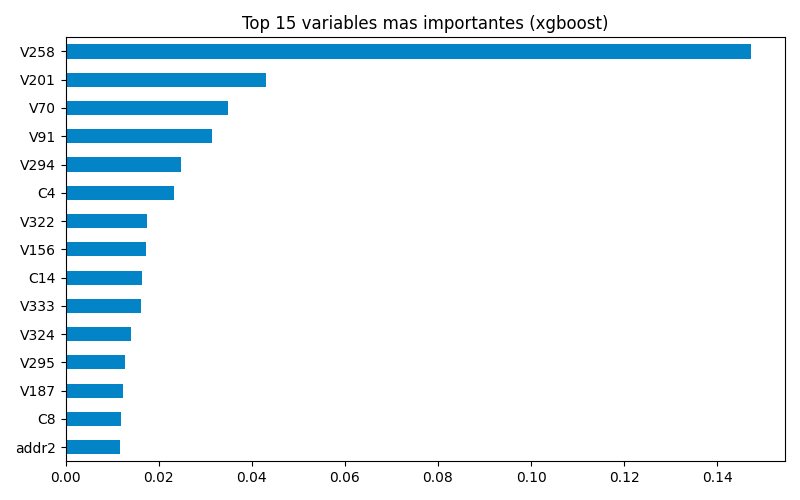

In [4]:
importances = pd.Series(best_model.feature_importances_, index=feature_cols)
top15 = importances.sort_values(ascending=False).head(15)
print(top15)

fig, ax = plt.subplots(figsize=(8, 5))
top15.sort_values().plot.barh(ax=ax, color='#0284c7')
ax.set_title(f'Top 15 variables mas importantes ({best_model_name})')
plt.tight_layout()
plt.savefig('../figures/05_feature_importance.png', dpi=110)
plt.show()

![Importancia de variables](../figures/05_feature_importance.png)

El top 15 está dominado por columnas anonimizadas originales del dataset (V*, C*, addr2). Al revisar el ranking completo, nuestras variables de ingeniería del notebook 02 quedan en posiciones bastante bajas: card1_txn_count_86400s en el puesto 187, has_identity en el 223, hour_of_day en el 231, card1_amt_mean_86400s en el 250 y day_of_week en el 309, de 397 en total. log_amt directamente tiene importancia 0, porque XGBoost al partir por umbrales no necesita la transformación logarítmica, ya puede separar usando el monto crudo. Preferimos reportar este hallazgo tal cual salió: el poder predictivo principal viene de las variables que ya venían de Vesta y Kaggle, y no tanto de las features nuevas que armamos nosotros, que aportan una señal marginal.

## 4. Selección del umbral costo-óptimo (métrica de decisión)

En vez de usar el umbral por defecto de 0.5, se recorre un rango de umbrales sobre val y se elige el que minimiza el costo de negocio definido en el checkpoint 1, sección 5: Costo = FN x $120 + FP x $15.

Umbral costo-optimo: 0.07  (costo=$254190)
Umbral 0.50 (default): costo=$354510
Ahorro vs. umbral 0.50: $100320 (28.3%)

Metricas con umbral costo-optimo: {'f1': 0.49523198974276783, 'precision': 0.3927300457549568, 'recall': 0.6701366297983083, 'roc_auc': 0.9205679756735856}


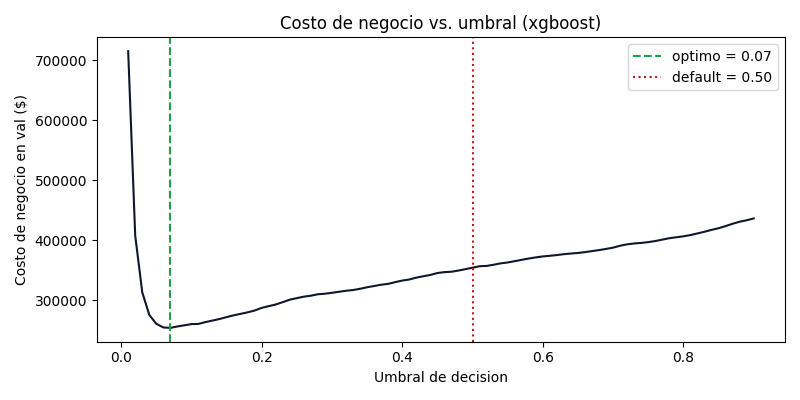

In [5]:
best_proba_val = val_probas[best_model_name]
thresholds = np.arange(0.01, 0.91, 0.01)
costs = [business_cost(y_val, (best_proba_val >= t).astype(int)) for t in thresholds]

best_idx = int(np.argmin(costs))
best_threshold = thresholds[best_idx]
cost_at_best = costs[best_idx]
cost_at_050 = business_cost(y_val, (best_proba_val >= 0.5).astype(int))

print(f'Umbral costo-optimo: {best_threshold:.2f}  (costo=${cost_at_best:.0f})')
print(f'Umbral 0.50 (default): costo=${cost_at_050:.0f}')
print(f'Ahorro vs. umbral 0.50: ${cost_at_050 - cost_at_best:.0f} ({(cost_at_050 - cost_at_best) / cost_at_050 * 100:.1f}%)')

y_pred_opt = (best_proba_val >= best_threshold).astype(int)
print()
print('Metricas con umbral costo-optimo:', compute_metrics(y_val, y_pred_opt, best_proba_val))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, costs, color='#0f172a')
ax.axvline(best_threshold, color='#16a34a', linestyle='--', label=f'optimo = {best_threshold:.2f}')
ax.axvline(0.5, color='#b91c1c', linestyle=':', label='default = 0.50')
ax.set_xlabel('Umbral de decision')
ax.set_ylabel('Costo de negocio en val ($)')
ax.set_title(f'Costo de negocio vs. umbral ({best_model_name})')
ax.legend()
plt.tight_layout()
plt.savefig('../figures/06_cost_vs_threshold.png', dpi=110)
plt.show()

![Costo vs umbral](../figures/06_cost_vs_threshold.png)

El umbral costo-óptimo resultó ser 0.07, en vez del 0.5 por defecto, con un ahorro de 28.3% en el costo de negocio sobre validación. Es evidencia concreta de por qué el checkpoint 1 definió la métrica de decisión con un umbral que se puede optimizar, en vez de dejarlo fijo.

## Conclusiones para el notebook 04

- El modelo seleccionado es XGBoost, con un umbral de decisión de 0.07 en vez de 0.5.
- El notebook 04 debe reentrenar este mismo modelo con el mismo umbral y evaluar su desempeño por bloque temporal sobre test.parquet, usando evaluation.evaluate_by_time_block, para ver si el rendimiento se degrada con el tiempo. Eso es algo que esta comparación en un solo corte de validación no puede mostrar.
- Los resultados de aquí son de un único split de validación. Antes de reportar cifras finales en el informe técnico hay que confirmarlas sobre test.parquet, que todavía no se ha usado para nada.